# Explore — 公園の名前で絞って比べる

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/u-kitazawa/rhinestone/blob/develop/showcase/04_explore.ipynb)

```python
view = frame[["名称", "geometry"]].to_crs(epsg=4326)
selected = view[view["名称"].str.contains(NAME_CONTAINS, regex=False, na=False)]
```

**NAME_CONTAINS** を「八汐」から「公園」「黒磯」などへ変えて、選ばれる地点を比べます。
Rhinestoneで見つけて開いたデータを、自分のPython処理へそのまま使えます。

出典：那須塩原市 建設部 保全管理課「公園 都市整備施設」（【那須塩原市】公園 都市整備）。
[元リソース](https://opendata-nasu.opendatastack.jp/dataset/shisetu-kouenn-tosisetibi/resource/d94a1299-e0fb-4c9a-9a9f-aac7dcb97763) · [配布データ](https://nasu-ckan.s3.amazonaws.com/ckan/resources/d94a1299-e0fb-4c9a-9a9f-aac7dcb97763/011201.json) · [CC BY 2.1 JP](https://creativecommons.org/licenses/by/2.1/jp/) · [利用規約](https://opendata-nasu.opendatastack.jp/pages/userpolicy)。
名称・位置を抽出し、表示用にEPSG:4326へ変換しています。写真・リンク先画像は取得しません。
2026-10-20確認、提供元の最終更新表示は2016-04-04。最新の公園一覧・営業状況ではありません。



In [1]:
import os
import subprocess
import sys

# 固定コミット。保守者のlocal smokeだけは、検証対象checkoutを明示して使用します。
if os.environ.get("RHINESTONE_SHOWCASE_LOCAL") != "1":
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "rhinestone @ git+https://github.com/u-kitazawa/rhinestone.git@9bae025b08357d23e5f5339c25a777a1445da176",
            "pyogrio==0.13.0",
            "geopandas==1.1.1",
            "matplotlib==3.10.7",
        ]
    )
else:
    print("Local smoke: explicit checkout and caller-owned dependencies")

Local smoke: explicit checkout and caller-owned dependencies


In [2]:
from rhinestone import FormatPreset, ProviderId, search

KEYWORD = "公園"
NAME_CONTAINS = "八汐"
SELECTED_URI = "https://nasu-ckan.s3.amazonaws.com/ckan/resources/d94a1299-e0fb-4c9a-9a9f-aac7dcb97763/011201.json"

In [3]:
results = None
results = search(
    text=KEYWORD,
    providers=[ProviderId.SEARCH_CKAN_JP],
    format=(FormatPreset.PYOGRIO,),
    limit=3,
)
for diagnostic in results.diagnostics:
    print(
        "Diagnostic:", diagnostic.source_id, diagnostic.reason, diagnostic.failure_type
    )
for candidate in results:
    print(candidate.title, candidate.format, candidate.uri)
if not results:
    if results.diagnostics:
        raise ValueError(
            "Providerの診断を確認してください。データ不在とは限りません。後で再実行できます。"
        )
    raise ValueError("検索0件です。KEYWORDを変更して検索し直してください。")

【那須塩原市】公園 都市整備 geojson https://nasu-ckan.s3.amazonaws.com/ckan/resources/d94a1299-e0fb-4c9a-9a9f-aac7dcb97763/011201.json
【那須塩原市】公園 都市整備 kml https://nasu-ckan.s3.amazonaws.com/ckan/resources/bb9c7539-7c06-434f-979a-b371f6e806a4/011201.kml
社会資本情報プラットフォーム（都市公園） geojson https://www.geospatial.jp/ckan/dataset/1c9f7b14-f0b3-4b92-af20-d032d40a5cc4/resource/10cd0164-623c-4d16-8372-22c6bbaa7429/download/01-0601.geojson


In [4]:
resource = None
matches = [candidate for candidate in results if candidate.uri == SELECTED_URI]
if len(matches) != 1:
    raise ValueError(
        "SELECTED_URIが一覧に一意にありません。一覧を確認し、URIを変更してこのセルから再実行してください。"
    )
resource = matches[0]
print("Selected:", resource.title, resource.format)

Selected: 【那須塩原市】公園 都市整備 geojson


In [5]:
import pyogrio

from rhinestone.errors import ResourceAccessError

frame = None
try:
    frame = resource.open("pyogrio", runtime=pyogrio)
except ResourceAccessError:
    print(
        "Open失敗：配布URL・権限・Runtimeのdriverを確認してください。検索の成功とは別です。"
    )
    raise
print("Features:", len(frame), "CRS:", frame.crs)

Features: 10 CRS: EPSG:4979


Matched: 2 / 10
八汐第一公園
八汐第二公園


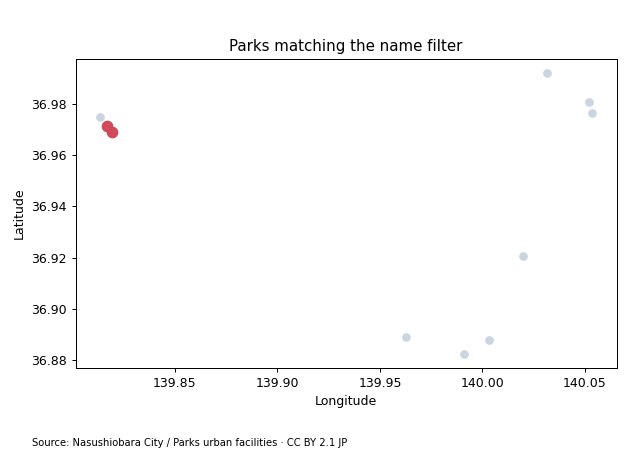

In [6]:
import matplotlib.pyplot as plt

if frame.empty or frame.crs is None or "名称" not in frame.columns:
    raise ValueError("名称・geometry・CRSのある非空データが必要です。")
view = frame[["名称", "geometry"]].to_crs(epsg=4326)
selected = view[view["名称"].str.contains(NAME_CONTAINS, regex=False, na=False)]
if selected.empty:
    raise ValueError(
        "名前に一致する公園がありません。NAME_CONTAINSを変更してください。"
    )
ax = view.plot(figsize=(7, 5), color="#cbd5e1", markersize=35)
selected.plot(ax=ax, color="#d1495b", markersize=70)
ax.set(title="Parks matching the name filter", xlabel="Longitude", ylabel="Latitude")
ax.figure.text(
    0.05,
    0.01,
    "Source: Nasushiobara City / Parks urban facilities · CC BY 2.1 JP",
    fontsize=8,
)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()
print("Matched:", len(selected), "/", len(view))
print(selected["名称"].to_string(index=False))

## 自分の処理へ

名前の絞り込みや描画はGeoPandas/Matplotlibが行います。Rhinestone CoreにGIS処理は追加しません。
別データで試す場合は[01](01_discover.ipynb)で探し、[02](02_open_vector.ipynb)の手順で容量・条件・選択URIを確認してください。
独立実行へ移すなら[03](03_portable_vector.ipynb)へ。内部の来歴は[発展編](advanced/discovery_lineage.ipynb)、
既知STACの詳細設定は[手入力の発展例](advanced/stac_explicit.ipynb)を参照します。
